# Pneumonia classifier V3: transfer learning

V2 was near-perfect on validation but flagged about half of the healthy test X-rays as pneumonia: features learned from scratch on ~4,000 images did not carry over to the test images. V3 changes four things:

1. **Transfer learning:** a DenseNet121 pretrained on ImageNet replaces the from-scratch CNN. A new classification head is trained first, then the top of the network is fine-tuned at a low learning rate.
2. **Data augmentation:** small rotations, shifts, zoom and contrast changes so the model is robust to differences between X-ray machines.
3. **Balanced class weights** computed from the class counts, instead of V2's hand-picked 12 : 1 ratio.
4. **224×224 input**, the resolution DenseNet was pretrained at.

The patient-grouped validation split and the evaluation are the same as V2, so the test results compare directly.

In [1]:
import os
import re
import glob
import random
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_auc_score,
                             precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

/Users/george/Documents/projects/Pneumonia-image-classifier/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow 2.18.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
DATA_DIR = 'data'
IMG_SIZE = 224
BATCH_SIZE = 32
HEAD_EPOCHS = 10
FINE_TUNE_EPOCHS = 20
TARGET_RECALL = 0.95

os.makedirs('models', exist_ok=True)
MODEL_PATH = os.path.join('models', f'v3_densenet121_{date.today().isoformat()}.keras')
class_names = ['NORMAL', 'PNEUMONIA']

## Data and validation split

Same as V2: the 16-image `val/` folder is merged into training and ~14% is held out, stratified by class and grouped by patient so no patient's X-rays appear in both sets. Paths are sorted so the split is the same on every machine.

In [3]:
def list_images(split):
    rows = []
    for label, name in enumerate(class_names):
        paths = sorted(glob.glob(os.path.join(DATA_DIR, split, name, '*.jpeg')))
        rows += [(p, label) for p in paths]
    return pd.DataFrame(rows, columns=['image', 'label'])

def patient_id(img_path):
    # person123_bacteria_456.jpeg -> person123, IM-0115-0001.jpeg -> IM-0115, NORMAL2-IM-0123-0001.jpeg -> NORMAL2-IM-0123
    return re.match(r'(person\d+|(?:NORMAL2-)?IM-\d+)', os.path.basename(img_path)).group(1)

pool_df = pd.concat([list_images('train'), list_images('val')], ignore_index=True)
test_df = list_images('test')

groups = pool_df['image'].map(patient_id)
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter.split(pool_df, pool_df['label'], groups))
train_df = pool_df.iloc[train_idx].reset_index(drop=True)
val_df = pool_df.iloc[val_idx].reset_index(drop=True)
assert not set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])

for name, df in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    counts = df['label'].value_counts().sort_index()
    print(f'{name:<11} {len(df):>5} images  (NORMAL {counts[0]}, PNEUMONIA {counts[1]})')

Train        4203 images  (NORMAL 861, PNEUMONIA 3342)
Validation    688 images  (NORMAL 147, PNEUMONIA 541)
Test          624 images  (NORMAL 234, PNEUMONIA 390)


## Input pipeline and augmentation

Images are streamed from disk with `tf.data` rather than loaded into one big array. Each X-ray is decoded as 3 channels (DenseNet expects RGB input), resized to 224×224 and cached in memory after the first epoch.

Augmentation is applied to training images only, with small ranges so the X-rays stay realistic. There are no horizontal flips: the heart sits on the left, so a flipped chest X-ray is anatomically wrong.

In [4]:
augment = keras.Sequential([
    layers.RandomRotation(0.03),                  # about ±10 degrees
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.15),
], name='augmentation')

def load_image(path, label):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df['image'].values, df['label'].values.astype('float32')))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(df), seed=SEED)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

2026-10-12 21:07:27.592135: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-12 21:07:27.592156: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-12 21:07:27.592158: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
I0000 00:00:1791835647.592379 1185844 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791835647.592582 1185844 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


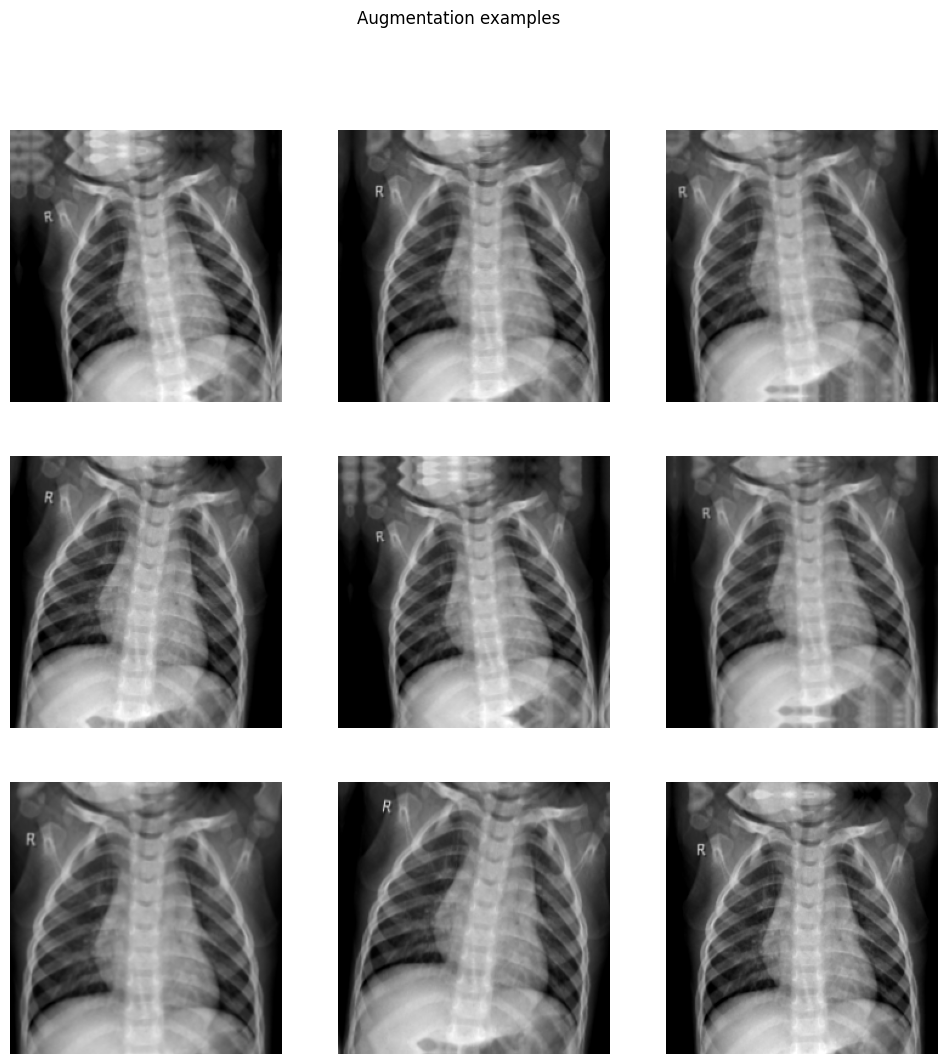

In [5]:
# Nine augmented versions of the same training X-ray
sample, _ = load_image(train_df['image'][0], 0)
plt.figure(figsize=(12, 12))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(tf.clip_by_value(augment(sample[None], training=True)[0], 0, 255).numpy().astype('uint8'))
    plt.axis('off')
plt.suptitle('Augmentation examples')
plt.show()

## Model

DenseNet121 pretrained on ImageNet, with its own classifier removed, followed by global average pooling, dropout and a single sigmoid output (probability of pneumonia).

The base is called with `training=False` so its batch-normalisation layers keep their pretrained statistics, even when its weights are unfrozen for fine-tuning.

In [6]:
base = DenseNet121(include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = preprocess_input(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,038,529 (26.85 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

## Phase 1: train the new head

Only the new final layer is trained, with the pretrained base frozen. Class weights are balanced from the class counts so NORMAL and PNEUMONIA images contribute equally to the loss.

In [7]:
counts = train_df['label'].value_counts().sort_index()
class_weight = {label: len(train_df) / (2 * n) for label, n in counts.items()}
print('Class weights:', {class_names[k]: round(v, 2) for k, v in class_weight.items()})

metrics = ['accuracy', keras.metrics.AUC(name='auc'), keras.metrics.Recall(name='recall')]

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=metrics)
head_history = model.fit(
    train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, class_weight=class_weight,
    callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)])

Class weights: {'NORMAL': 2.44, 'PNEUMONIA': 0.63}
Epoch 1/10


2026-10-12 21:07:30.595515: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


132/132 ━━━━━━━━━━━━━━━━━━━━ 59s 374ms/step - accuracy: 0.6819 - auc: 0.7272 - loss: 0.5838 - recall: 0.6903 - val_accuracy: 0.9041 - val_auc: 0.9767 - val_loss: 0.2716 - val_recall: 0.8891
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 42s 313ms/step - accuracy: 0.8831 - auc: 0.9486 - loss: 0.3095 - recall: 0.8816 - val_accuracy: 0.9172 - val_auc: 0.9812 - val_loss: 0.2167 - val_recall: 0.9057
Epoch 3/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 43s 318ms/step - accuracy: 0.9015 - auc: 0.9673 - loss: 0.2498 - recall: 0.8980 - val_accuracy: 0.9259 - val_auc: 0.9838 - val_loss: 0.1943 - val_recall: 0.9150
Epoch 4/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 40s 301ms/step - accuracy: 0.8990 - auc: 0.9663 - loss: 0.2405 - recall: 0.8985 - val_accuracy: 0.9375 - val_auc: 0.9849 - val_loss: 0.1731 - val_recall: 0.9261
Epoch 5/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 40s 300ms/step - accuracy: 0.9193 - auc: 0.9737 - loss: 0.2134 - recall: 0.9170 - val_accuracy: 0.9404 - val_auc: 0.9853 - val_loss: 0.1699 - val_recall: 0.9279
Epoch 

## Phase 2: fine-tune the top of DenseNet

The last dense block (`conv5`) is unfrozen and trained together with the head at a learning rate 100× lower, so the pretrained features are adjusted to X-rays rather than overwritten. The best model by validation loss is saved to `models/`.

In [8]:
base.trainable = True
fine_tune_from = [layer.name for layer in base.layers].index('conv5_block1_0_bn')
for layer in base.layers[:fine_tune_from]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=metrics)
fine_tune_history = model.fit(
    train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS, class_weight=class_weight,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7),
        ModelCheckpoint(MODEL_PATH, monitor='val_loss', save_best_only=True),
    ])
print('Best model saved to', MODEL_PATH)

Epoch 1/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 117s 761ms/step - accuracy: 0.8926 - auc: 0.9509 - loss: 0.5919 - recall: 0.9613 - val_accuracy: 0.9462 - val_auc: 0.9869 - val_loss: 0.1243 - val_recall: 0.9630 - learning_rate: 1.0000e-05
Epoch 2/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 111s 831ms/step - accuracy: 0.9464 - auc: 0.9812 - loss: 0.1837 - recall: 0.9555 - val_accuracy: 0.9520 - val_auc: 0.9881 - val_loss: 0.1323 - val_recall: 0.9556 - learning_rate: 1.0000e-05
Epoch 3/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 115s 860ms/step - accuracy: 0.9479 - auc: 0.9827 - loss: 0.1706 - recall: 0.9506 - val_accuracy: 0.9564 - val_auc: 0.9898 - val_loss: 0.1313 - val_recall: 0.9538 - learning_rate: 1.0000e-05
Epoch 4/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 110s 823ms/step - accuracy: 0.9405 - auc: 0.9820 - loss: 0.1689 - recall: 0.9410 - val_accuracy: 0.9549 - val_auc: 0.9904 - val_loss: 0.1434 - val_recall: 0.9464 - learning_rate: 3.0000e-06
Epoch 5/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 115s 860ms/step - accuracy: 0.9489 - auc

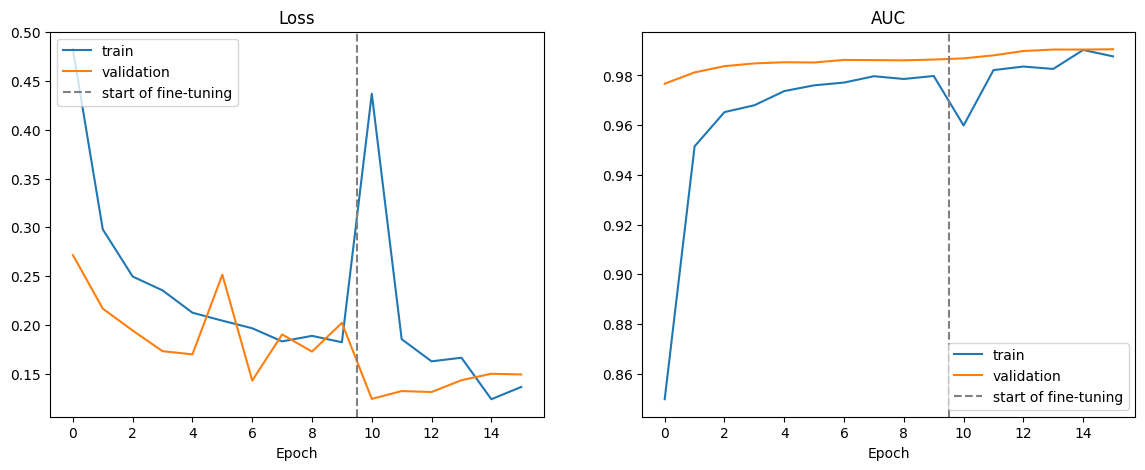

In [9]:
history = {k: head_history.history[k] + fine_tune_history.history[k] for k in ['loss', 'val_loss', 'auc', 'val_auc']}
fine_tune_start = len(head_history.history['loss'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ['loss', 'auc']):
    ax.plot(history[metric], label='train')
    ax.plot(history['val_' + metric], label='validation')
    ax.axvline(fine_tune_start - 0.5, color='grey', linestyle='--', label='start of fine-tuning')
    ax.set_title(metric.upper() if metric == 'auc' else metric.capitalize())
    ax.set_xlabel('Epoch')
    ax.legend()
plt.show()

## Evaluation

Same as V2: a confusion matrix and per-class report at the default 0.5 threshold, ROC-AUC with ROC and precision-recall curves, then a threshold tuned on the **validation set** to keep pneumonia recall at or above `TARGET_RECALL`, applied to the test set once.

In [10]:
val_probs = model.predict(val_ds, verbose=0).ravel()
test_probs = model.predict(test_ds, verbose=0).ravel()
y_val = val_df['label'].values
y_test = test_df['label'].values

def evaluate(threshold, title):
    y_pred = (test_probs >= threshold).astype(int)
    print(f'{title} (threshold = {threshold:.3f})')
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, cmap='Blues')
    plt.title(title)
    plt.show()

Default threshold (threshold = 0.500)
              precision    recall  f1-score   support

      NORMAL      0.939     0.530     0.678       234
   PNEUMONIA      0.776     0.979     0.866       390

    accuracy                          0.811       624
   macro avg      0.858     0.755     0.772       624
weighted avg      0.838     0.811     0.795       624



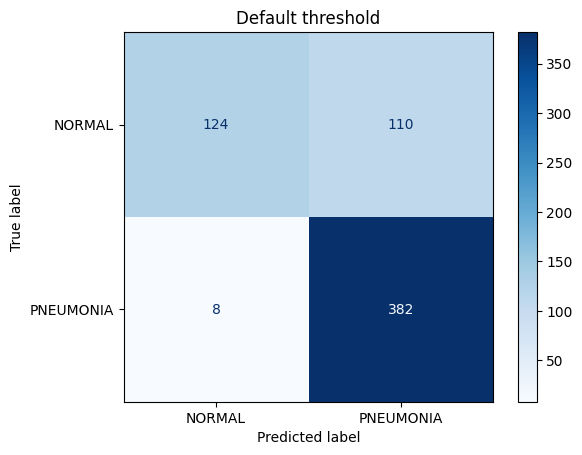

In [11]:
evaluate(0.5, 'Default threshold')

Test ROC-AUC: 0.961


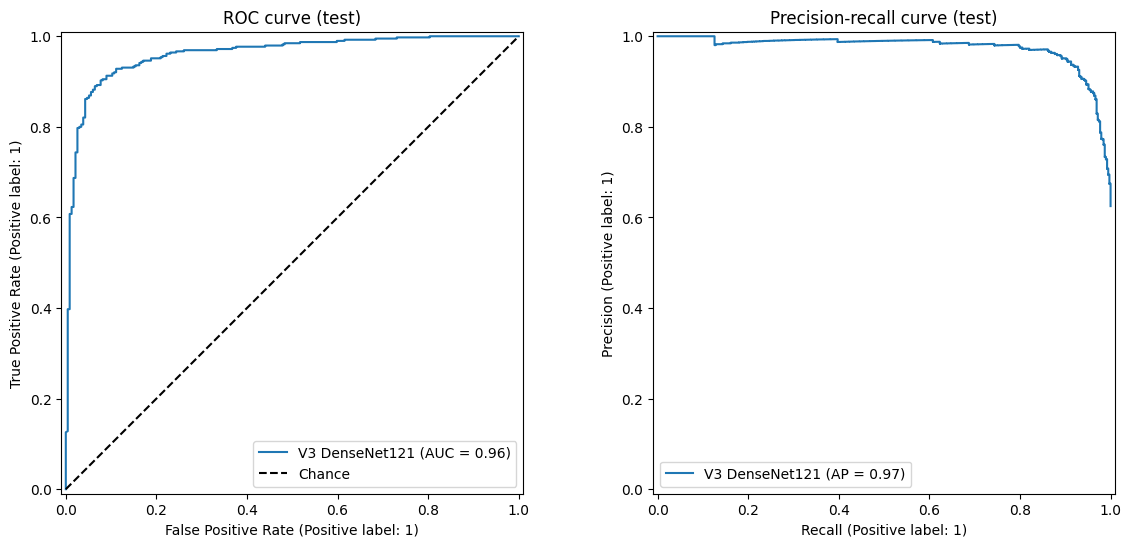

In [12]:
print(f'Test ROC-AUC: {roc_auc_score(y_test, test_probs):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
RocCurveDisplay.from_predictions(y_test, test_probs, name='V3 DenseNet121', ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--', label='Chance')
axes[0].legend()
axes[0].set_title('ROC curve (test)')
PrecisionRecallDisplay.from_predictions(y_test, test_probs, name='V3 DenseNet121', ax=axes[1])
axes[1].set_title('Precision-recall curve (test)')
plt.show()

### Threshold tuning

The highest threshold whose validation recall is still at least `TARGET_RECALL`, i.e. the fewest false alarms that still meet the recall target.

Chosen threshold: 0.749 (validation recall 0.950, precision 0.990)
Tuned threshold (target recall 0.95) (threshold = 0.749)
              precision    recall  f1-score   support

      NORMAL      0.933     0.654     0.769       234
   PNEUMONIA      0.824     0.972     0.892       390

    accuracy                          0.853       624
   macro avg      0.878     0.813     0.830       624
weighted avg      0.865     0.853     0.846       624



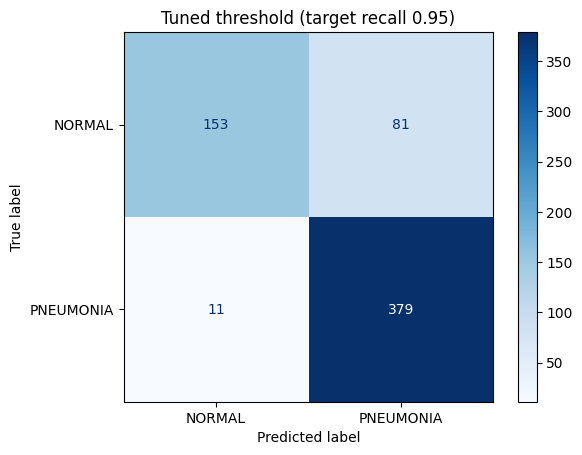

In [13]:
precision, recall, thresholds = precision_recall_curve(y_val, val_probs)
# recall[i] and precision[i] belong to thresholds[i]; the final entries have no threshold
meets_target = recall[:-1] >= TARGET_RECALL
best_threshold = thresholds[meets_target].max()
i = np.where(thresholds == best_threshold)[0][0]
print(f'Chosen threshold: {best_threshold:.3f} '
      f'(validation recall {recall[i]:.3f}, precision {precision[i]:.3f})')

evaluate(best_threshold, f'Tuned threshold (target recall {TARGET_RECALL})')